#### EfficientFrontier решает задачу QP для N равномерно распределённых точек и соединяет их.

#### Есть возможность найти вес оптимального портфеля, при ненулевой безрисковой ставке

In [1]:
from pypfopt import EfficientFrontier, plotting
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

### На подгруженных данных

In [2]:
# Загрузка данных
prices = pd.read_csv('prices_processed.csv', index_col=0, parse_dates=True)
n = 20
prices_n = prices.iloc[:, :n]
returns = np.log(prices_n / prices_n.shift(1)).dropna()

mu = returns.mean().to_numpy(dtype=np.float64) * 252
S  = returns.cov().to_numpy(dtype=np.float64) * 252

print("------------------")
print("mu : \n", mu)
print("------------------")
print("Sigma : \n", S)
print("------------------")

------------------
mu : 
 [-0.3936586   0.53329848  0.26482815  0.77746506 -0.47629516 -0.06418228
  0.20865603  0.29039578 -0.69437042  0.65721517  0.48124672  0.19706384
  0.27151714  0.3311383  -0.38062582 -0.13449494 -0.32069282 -0.0250013
  0.15199202  0.11907253]
------------------
Sigma : 
 [[ 1.37629758e-01 -1.13602906e-03  8.05894833e-03  1.27313275e-02
   1.43504333e-03  1.22634409e-03  1.55742097e-02  2.84332143e-03
   1.71482021e-02 -1.23010177e-02  6.17277476e-03 -4.81143026e-03
  -1.59271739e-03 -1.81070990e-03  3.60078767e-03  2.72476992e-03
  -4.56940065e-03 -2.24053949e-03  8.10209341e-03 -2.22404138e-04]
 [-1.13602906e-03  1.21717732e-01 -3.14187051e-04  9.13967461e-04
   3.24880146e-03  2.55762782e-03 -8.16556996e-03  7.62501249e-03
   2.59514422e-03  2.80912191e-03 -1.92731193e-02 -2.23929769e-03
  -4.29448550e-02  4.34202033e-03  1.86344324e-03  1.06537254e-02
   1.43044452e-02 -3.06019346e-03  1.01713982e-02 -2.69506061e-03]
 [ 8.05894833e-03 -3.14187051e-04  8.07

In [3]:
ef = EfficientFrontier(mu, S, weight_bounds=(0, 1))



In [15]:
N = 100 # Задаём число точек

# 1. Находим минимальный риск (нижняя точка границы)
ef_min = EfficientFrontier(mu, S, weight_bounds=(0, 1))
ef_min.min_volatility()
ret_min, vol_min, _ = ef_min.portfolio_performance()

# 2. Задаем сетку доходностей от минимальной до максимальной
ret_max = np.max(mu) * 0.999 # Чуть меньше максимума, чтобы избежать ошибок
target_returns = np.linspace(ret_min, ret_max, N) # равномерное распределение N точек

returns_ef = []
risks_ef = []
weights_ef = []

# 3. Проходимся по сетке и считаем портфели
for tr in target_returns:
    ef_i = EfficientFrontier(mu, S, weight_bounds=(0, 1))
    try:
        ef_i.efficient_return(target_return=tr)
        r, v, _ = ef_i.portfolio_performance(verbose=False)
        returns_ef.append(r)
        risks_ef.append(v)
        
        # ИСПРАВЛЕНИЕ ЗДЕСЬ: убираем .values() и используем flatten()
        weights_ef.append(np.array(ef_i.weights).flatten())
        
    except ValueError:
        pass # Пропускаем недостижимые точки

print(f"Сгенерировано точек: {len(returns_ef)}")

Сгенерировано точек: 100


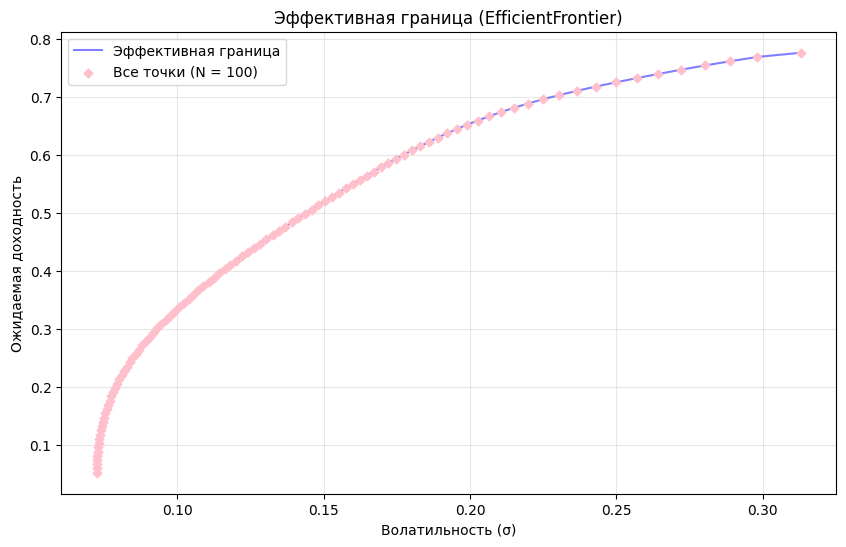

In [16]:
fig, ax = plt.subplots(figsize=(10, 6))

# 1. Рисуем линию границы и все сгенерированные точки
ax.plot(risks_ef, returns_ef, 'b-', alpha=0.5, label='Эффективная граница')
ax.scatter(
    risks_ef,
    returns_ef,
    marker='D',        
    s=20,              
    c='pink',           
    zorder=5,          
    label=f'Все точки (N = {len(risks_ef)})'
)

ax.set_xlabel('Волатильность (σ)')
ax.set_ylabel('Ожидаемая доходность')
ax.set_title('Эффективная граница (EfficientFrontier)')
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()

### Использование фильтра угловых портфелей, оставляя только те, где меняется активное множество.

In [12]:
def filter_frontier(returns, risks, weights, tol=1e-4):
    """
    Фильтрует угловые портфели, оставляя только те, где меняется активный набор.
    """
    returns = np.asarray(returns, dtype=np.float64)
    risks = np.asarray(risks, dtype=np.float64)
    weights = np.asarray(weights, dtype=np.float64)
    
    if len(weights) == 0:
        return [], [], []

    filtered_returns = []
    filtered_risks = []
    filtered_weights = []

    def get_active_mask(w):
        return (w > tol) & (w < 1 - tol)

    current_mask = get_active_mask(weights[0])
    filtered_returns.append(returns[0])
    filtered_risks.append(risks[0])
    filtered_weights.append(weights[0])

    for i in range(1, len(weights)):
        new_mask = get_active_mask(weights[i])
        if not np.array_equal(current_mask, new_mask):
            filtered_returns.append(returns[i])
            filtered_risks.append(risks[i])
            filtered_weights.append(weights[i])
            current_mask = new_mask

    if not np.array_equal(filtered_weights[-1], weights[-1]):
        filtered_returns.append(returns[-1])
        filtered_risks.append(risks[-1])
        filtered_weights.append(weights[-1])

    return np.array(filtered_returns), np.array(filtered_risks), np.array(filtered_weights)

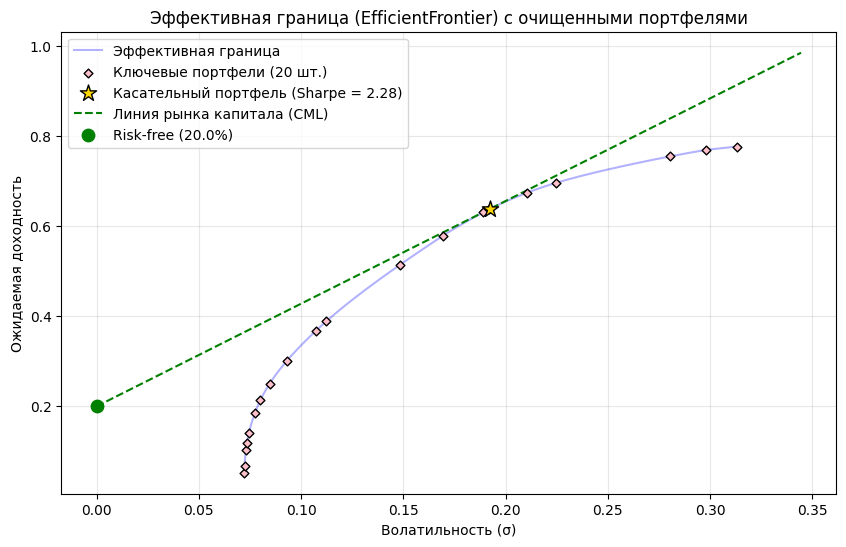

In [17]:
f_returns, f_risks, f_weights = filter_frontier(returns_ef, risks_ef, weights_ef)

# 1. Получаем веса касательного портфеля через EfficientFrontier
rf = 0.2 # Задаем безрисковую ставку
ef_sharpe = EfficientFrontier(mu, S, weight_bounds=(0, 1))
max_sharpe_weights = ef_sharpe.max_sharpe(risk_free_rate=rf)

# 2. Считаем доходность, риск и Sharpe
opt_ret, opt_vol, max_sharpe_ratio = ef_sharpe.portfolio_performance(
    risk_free_rate=rf,
    verbose=False
)

# 3. Строим график
fig, ax = plt.subplots(figsize=(10, 6))

# Линия
ax.plot(risks_ef, returns_ef, 'b-', alpha=0.3, label='Эффективная граница')

# Отфильтрованные угловые портфели
ax.scatter(f_risks, f_returns, 
           marker='D', s=20, c='pink', edgecolors='black', zorder=5, 
           label=f'Ключевые портфели ({len(f_returns)} шт.)')

# Касательный портфель
ax.scatter([opt_vol], [opt_ret], 
           marker='*', s=150, c='gold', edgecolors='black', zorder=6, 
           label=f'Касательный портфель (Sharpe = {max_sharpe_ratio:.2f})')

# Линия рынка капитала (CML)
x_max = max(risks_ef) * 1.1
x_cml = np.linspace(0, x_max, 100)
y_cml = rf + max_sharpe_ratio * x_cml
ax.plot(x_cml, y_cml, 'g--', linewidth=1.5, label='Линия рынка капитала (CML)')

# Безрисковая ставка
ax.scatter([0], [rf], marker='o', s=80, c='green', zorder=6, label=f'Risk-free ({rf*100}%)')

ax.set_xlabel('Волатильность (σ)')
ax.set_ylabel('Ожидаемая доходность')
ax.set_title('Эффективная граница (EfficientFrontier) с очищенными портфелями')
ax.legend()
ax.grid(True, alpha=0.3)

plt.show()